<a href="https://colab.research.google.com/github/saglamkubra/Brain-Tumor-MRI-Classification-Segmentation/blob/main/notebooks/ViT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

proje_yolu = "/content/drive/MyDrive/Beyin_Tumoru_Projesi"

zip_yolu = os.path.join(proje_yolu, "Brain_Tumor_MRI_Dataset.zip")
csv_yolu = os.path.join(proje_yolu, "veri_bolunmesi")

print("Veri seti ZIP mevcut mu:", os.path.exists(zip_yolu))
print("CSV klasörü mevcut mu:", os.path.exists(csv_yolu))
print("Train CSV mevcut mu:", os.path.exists(os.path.join(csv_yolu, "train.csv")))
print("Validation CSV mevcut mu:", os.path.exists(os.path.join(csv_yolu, "val.csv")))
print("Test CSV mevcut mu:", os.path.exists(os.path.join(csv_yolu, "test.csv")))

Veri seti ZIP mevcut mu: True
CSV klasörü mevcut mu: True
Train CSV mevcut mu: True
Validation CSV mevcut mu: True
Test CSV mevcut mu: True


In [ ]:
import torch
import torchvision
import torch.nn as nn
import torch.optim as optim

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

import os
import zipfile

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA kullanılabilir mi:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
CUDA kullanılabilir mi: True
GPU: Tesla T4


In [ ]:
if not os.path.exists("/content/Training") or not os.path.exists("/content/Testing"):
    with zipfile.ZipFile(zip_yolu, "r") as zip_ref:
        zip_ref.extractall("/content")

print("Training klasörü mevcut mu:", os.path.exists("/content/Training"))
print("Testing klasörü mevcut mu:", os.path.exists("/content/Testing"))

Training klasörü mevcut mu: True
Testing klasörü mevcut mu: True


In [ ]:
print("Training:", os.path.exists("/content/Training"))
print("Testing:", os.path.exists("/content/Testing"))
print("ZIP:", os.path.exists(zip_yolu))

Training: True
Testing: True
ZIP: True


In [ ]:
train_df = pd.read_csv(os.path.join(csv_yolu, "train.csv"))
val_df = pd.read_csv(os.path.join(csv_yolu, "val.csv"))
test_df = pd.read_csv(os.path.join(csv_yolu, "test.csv"))

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

print("\nEğitim sınıf dağılımı:")
print(train_df["sinif"].value_counts())

Train: (4480, 2)
Validation: (1120, 2)
Test: (1600, 2)

Eğitim sınıf dağılımı:
sinif
glioma        1120
meningioma    1120
notumor       1120
pituitary     1120
Name: count, dtype: int64


In [ ]:
siniflar = {
    "glioma": 0,
    "meningioma": 1,
    "notumor": 2,
    "pituitary": 3
}

def dosya_yolu_kontrol(dataframe):
    return dataframe["dosya"].apply(
        lambda x: os.path.exists(os.path.join("/content", x))
    ).all()

print("Train görüntüleri mevcut mu:", dosya_yolu_kontrol(train_df))
print("Validation görüntüleri mevcut mu:", dosya_yolu_kontrol(val_df))
print("Test görüntüleri mevcut mu:", dosya_yolu_kontrol(test_df))

print("\nSınıf sıralaması:", siniflar)

Train görüntüleri mevcut mu: True
Validation görüntüleri mevcut mu: True
Test görüntüleri mevcut mu: True

Sınıf sıralaması: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}


In [ ]:
IMG_SIZE = 224
BATCH_SIZE = 32

vit_train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

vit_eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("ViT görüntü dönüşümleri hazır.")
print("Görüntü boyutu:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)

ViT görüntü dönüşümleri hazır.
Görüntü boyutu: 224
Batch size: 32


In [ ]:
class BrainTumorViTDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        dosya = self.dataframe.iloc[index]["dosya"]
        sinif = self.dataframe.iloc[index]["sinif"]

        yol = os.path.join("/content", dosya)

        goruntu = Image.open(yol).convert("RGB")

        if self.transform:
            goruntu = self.transform(goruntu)

        etiket = siniflar[sinif]

        return goruntu, etiket


print("ViT veri sınıfı oluşturuldu.")

ViT veri sınıfı oluşturuldu.


In [ ]:
train_dataset = BrainTumorViTDataset(
    train_df,
    transform=vit_train_transform
)

val_dataset = BrainTumorViTDataset(
    val_df,
    transform=vit_eval_transform
)

test_dataset = BrainTumorViTDataset(
    test_df,
    transform=vit_eval_transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

print("Train batch sayısı:", len(train_loader))
print("Validation batch sayısı:", len(val_loader))
print("Test batch sayısı:", len(test_loader))

Train batch sayısı: 140
Validation batch sayısı: 35
Test batch sayısı: 50


In [ ]:
goruntuler, etiketler = next(iter(train_loader))

print("Görüntü batch boyutu:", goruntuler.shape)
print("Etiket batch boyutu:", etiketler.shape)
print("İlk 10 etiket:", etiketler[:10].tolist())

Görüntü batch boyutu: torch.Size([32, 3, 224, 224])
Etiket batch boyutu: torch.Size([32])
İlk 10 etiket: [3, 2, 3, 3, 3, 0, 2, 3, 1, 3]


In [ ]:
from torchvision.models import vit_b_16, ViT_B_16_Weights

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ImageNet üzerinde önceden eğitilmiş ViT modelini yükle
model = vit_b_16(weights=ViT_B_16_Weights.DEFAULT)

# Son katmanı 4 sınıfa göre düzenle
model.heads.head = nn.Linear(
    model.heads.head.in_features,
    4
)

model = model.to(device)

print("ViT modeli oluşturuldu.")
print("Model cihazı:", device)
print("Sınıf sayısı:", model.heads.head.out_features)
print("Toplam parametre sayısı:", sum(p.numel() for p in model.parameters()))

Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:04<00:00, 79.0MB/s]


ViT modeli oluşturuldu.
Model cihazı: cuda
Sınıf sayısı: 4
Toplam parametre sayısı: 85801732


In [ ]:
BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

print("Yeni batch size:", BATCH_SIZE)
print("Train batch sayısı:", len(train_loader))
print("Validation batch sayısı:", len(val_loader))
print("Test batch sayısı:", len(test_loader))

Yeni batch size: 16
Train batch sayısı: 280
Validation batch sayısı: 70
Test batch sayısı: 100


In [ ]:
# Önce ViT'nin önceden öğrenilmiş katmanlarını dondur
for param in model.parameters():
    param.requires_grad = False

# Yalnızca sınıflandırma katmanını eğit
for param in model.heads.head.parameters():
    param.requires_grad = True

criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    model.heads.head.parameters(),
    lr=0.001,
    weight_decay=0.01
)

EPOCHS = 10

print("Loss Function:", criterion)
print("Optimizer: AdamW")
print("Learning Rate: 0.001")
print("Epoch sayısı:", EPOCHS)
print("Eğitilebilir parametre sayısı:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))

Loss Function: CrossEntropyLoss()
Optimizer: AdamW
Learning Rate: 0.001
Epoch sayısı: 10
Eğitilebilir parametre sayısı: 3076


In [ ]:
import copy
import time

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

best_val_loss = float("inf")
model_kayit_yolu = os.path.join(proje_yolu, "modeller", "vit_best.pth")
os.makedirs(os.path.dirname(model_kayit_yolu), exist_ok=True)

for epoch in range(EPOCHS):
    baslangic = time.time()

    # Eğitim
    model.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        train_correct += (predicted == labels).sum().item()
        train_total += labels.size(0)

    train_loss /= train_total
    train_acc = train_correct / train_total

    # Doğrulama
    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            val_correct += (predicted == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    # En iyi modeli kaydet
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save({
            "model_state_dict": model.state_dict(),
            "epoch": epoch + 1,
            "val_loss": val_loss,
            "val_acc": val_acc
        }, model_kayit_yolu)

    sure = time.time() - baslangic

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc*100:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc*100:.2f}% | "
        f"Süre: {sure:.1f} sn"
    )

print("\nEğitim tamamlandı.")
print("En iyi doğrulama kaybı:", round(best_val_loss, 4))
print("Model kaydedildi:", model_kayit_yolu)

Epoch [1/10] Train Loss: 0.4738 | Train Acc: 83.17% | Val Loss: 0.3226 | Val Acc: 88.39% | Süre: 143.7 sn
Epoch [2/10] Train Loss: 0.2775 | Train Acc: 90.20% | Val Loss: 0.2621 | Val Acc: 90.45% | Süre: 147.7 sn
Epoch [3/10] Train Loss: 0.2353 | Train Acc: 91.41% | Val Loss: 0.2360 | Val Acc: 91.16% | Süre: 147.5 sn
Epoch [4/10] Train Loss: 0.2077 | Train Acc: 92.61% | Val Loss: 0.2209 | Val Acc: 92.68% | Süre: 146.8 sn
Epoch [5/10] Train Loss: 0.1839 | Train Acc: 93.44% | Val Loss: 0.2017 | Val Acc: 92.41% | Süre: 147.4 sn
Epoch [6/10] Train Loss: 0.1764 | Train Acc: 93.66% | Val Loss: 0.1898 | Val Acc: 93.04% | Süre: 146.9 sn
Epoch [7/10] Train Loss: 0.1647 | Train Acc: 94.31% | Val Loss: 0.1948 | Val Acc: 93.48% | Süre: 145.8 sn
Epoch [8/10] Train Loss: 0.1608 | Train Acc: 94.24% | Val Loss: 0.1810 | Val Acc: 94.20% | Süre: 152.0 sn
Epoch [9/10] Train Loss: 0.1501 | Train Acc: 94.82% | Val Loss: 0.1799 | Val Acc: 93.30% | Süre: 147.4 sn
Epoch [10/10] Train Loss: 0.1422 | Train Acc: 

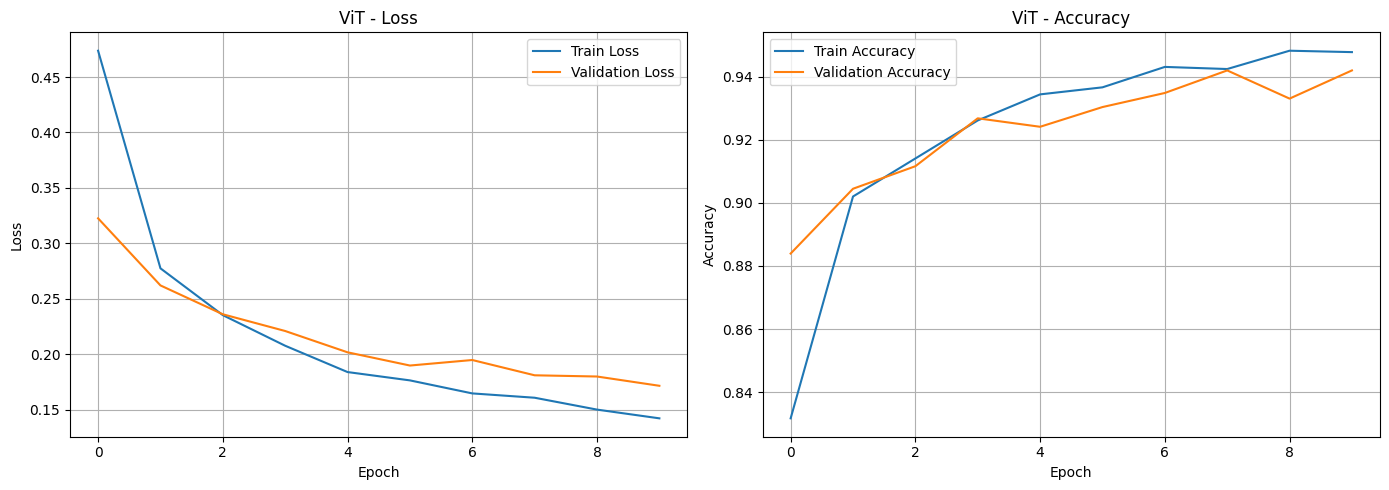

Grafikler kaydedildi: /content/drive/MyDrive/Beyin_Tumoru_Projesi/results/vit_training_curves.png


In [ ]:
results_yolu = os.path.join(proje_yolu, "results")
os.makedirs(results_yolu, exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss grafiği
axes[0].plot(history["train_loss"], label="Train Loss")
axes[0].plot(history["val_loss"], label="Validation Loss")
axes[0].set_title("ViT - Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

# Accuracy grafiği
axes[1].plot(history["train_acc"], label="Train Accuracy")
axes[1].plot(history["val_acc"], label="Validation Accuracy")
axes[1].set_title("ViT - Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()

grafik_yolu = os.path.join(results_yolu, "vit_training_curves.png")
plt.savefig(grafik_yolu, dpi=300, bbox_inches="tight")
plt.show()

print("Grafikler kaydedildi:", grafik_yolu)

In [ ]:
checkpoint = torch.load(model_kayit_yolu, map_location=device)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Yüklenen en iyi epoch:", checkpoint["epoch"])
print("Validation Loss:", round(checkpoint["val_loss"], 4))
print("Validation Accuracy:", f'{checkpoint["val_acc"]*100:.2f}%')

Yüklenen en iyi epoch: 10
Validation Loss: 0.1715
Validation Accuracy: 94.20%


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

model.eval()

tum_tahminler = []
tum_gercek_etiketler = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        _, predicted = torch.max(outputs, 1)

        tum_tahminler.extend(predicted.cpu().numpy())
        tum_gercek_etiketler.extend(labels.numpy())

vit_accuracy = accuracy_score(tum_gercek_etiketler, tum_tahminler)
vit_precision = precision_score(tum_gercek_etiketler, tum_tahminler, average="macro")
vit_recall = recall_score(tum_gercek_etiketler, tum_tahminler, average="macro")
vit_f1 = f1_score(tum_gercek_etiketler, tum_tahminler, average="macro")

print("ViT TEST SONUÇLARI")
print("-----------------------")
print(f"Accuracy:  {vit_accuracy*100:.2f}%")
print(f"Precision: {vit_precision*100:.2f}%")
print(f"Recall:    {vit_recall*100:.2f}%")
print(f"F1-Score:  {vit_f1*100:.2f}%")

print("\nSınıf Bazlı Sonuçlar:")
print(classification_report(
    tum_gercek_etiketler,
    tum_tahminler,
    target_names=list(siniflar.keys()),
    digits=4
))

ViT TEST SONUÇLARI
-----------------------
Accuracy:  90.25%
Precision: 91.09%
Recall:    90.25%
F1-Score:  90.05%

Sınıf Bazlı Sonuçlar:
              precision    recall  f1-score   support

      glioma     0.9831    0.7275    0.8362       400
  meningioma     0.7978    0.9175    0.8535       400
     notumor     0.9365    0.9950    0.9648       400
   pituitary     0.9260    0.9700    0.9475       400

    accuracy                         0.9025      1600
   macro avg     0.9109    0.9025    0.9005      1600
weighted avg     0.9109    0.9025    0.9005      1600



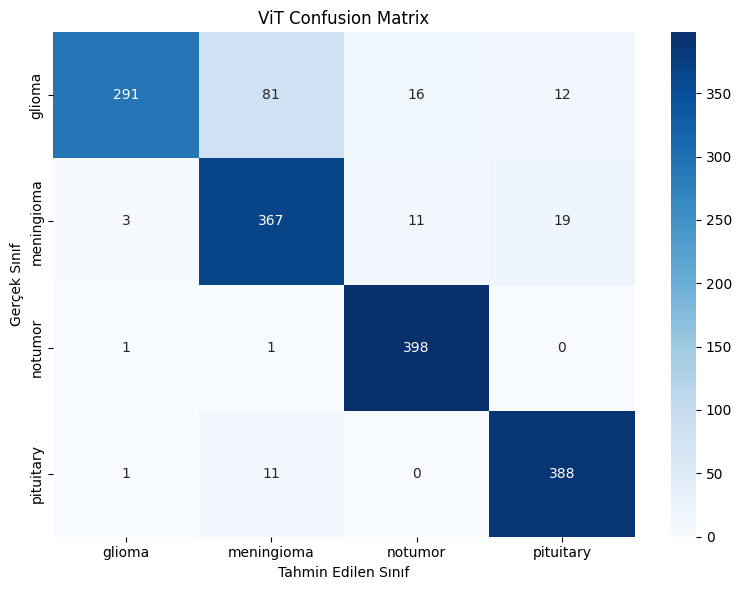

Confusion matrix kaydedildi: /content/drive/MyDrive/Beyin_Tumoru_Projesi/results/vit_confusion_matrix.png


In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(
    tum_gercek_etiketler,
    tum_tahminler
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=list(siniflar.keys()),
    yticklabels=list(siniflar.keys())
)

plt.xlabel("Tahmin Edilen Sınıf")
plt.ylabel("Gerçek Sınıf")
plt.title("ViT Confusion Matrix")
plt.tight_layout()

cm_yolu = os.path.join(results_yolu, "vit_confusion_matrix.png")
plt.savefig(cm_yolu, dpi=300, bbox_inches="tight")
plt.show()

print("Confusion matrix kaydedildi:", cm_yolu)